In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

In [20]:
df = pd.read_csv(r"C:\Trabajos\anfibia-unsam\data\processed\corpus_anfibia_lematizado.csv")

In [21]:
df.columns

Index(['doc_id', 'ID', 'source_url', 'title_text', 'tagline', 'autor_names',
       'post_date', 'post_year', 'category', 'post_tag', 'text_type',
       'document_text_final', 'document_text_original'],
      dtype='str')

In [22]:
df.category.unique()

<ArrowStringArray>
[                                                                                      'Política y Economía',
                                                                                               'Tecnologías',
                                                                                                  'Culturas',
                                                                                      'Políticas de géneros',
                                                                                               'Amor y sexo',
                                                                                                     'Otras',
                                                                                                  'Ambiente',
                                                                                                     'Salud',
                                                                                                 'Edu

In [23]:
df['category'].nunique()

31

In [24]:
df.category.value_counts()

category
Política y Economía                                                                                          1349
Culturas                                                                                                      985
Políticas de géneros                                                                                          521
Otras                                                                                                         161
Salud                                                                                                         117
Ambiente                                                                                                      100
Tecnologías                                                                                                    98
Educación                                                                                                      75
Amor y sexo                                                                    

In [25]:
otras = df[df['category']=='Otras']
otras.shape


(161, 13)

In [26]:
otras = df[df['category'].fillna('').str.contains('Otras')]

In [27]:
df.columns

Index(['doc_id', 'ID', 'source_url', 'title_text', 'tagline', 'autor_names',
       'post_date', 'post_year', 'category', 'post_tag', 'text_type',
       'document_text_final', 'document_text_original'],
      dtype='str')

In [28]:
otras.category.count()
otras.category.unique()

<ArrowStringArray>
['Otras', 'Otras; Política y Economía', 'Amor y sexo; Otras']
Length: 3, dtype: str

In [29]:
otras.loc[otras['category'] != 'Otras', 'category'] = 'Otras_secu'

In [30]:
otras.info()

<class 'pandas.DataFrame'>
Index: 165 entries, 23 to 3531
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   doc_id                  165 non-null    int64
 1   ID                      165 non-null    int64
 2   source_url              165 non-null    str  
 3   title_text              165 non-null    str  
 4   tagline                 107 non-null    str  
 5   autor_names             84 non-null     str  
 6   post_date               165 non-null    str  
 7   post_year               165 non-null    int64
 8   category                165 non-null    str  
 9   post_tag                61 non-null     str  
 10  text_type               56 non-null     str  
 11  document_text_final     165 non-null    str  
 12  document_text_original  165 non-null    str  
dtypes: int64(3), str(10)
memory usage: 3.3 MB


In [31]:
otras = otras[['doc_id','title_text','post_date','post_year','category']]
otras.info()

<class 'pandas.DataFrame'>
Index: 165 entries, 23 to 3531
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   doc_id      165 non-null    int64
 1   title_text  165 non-null    str  
 2   post_date   165 non-null    str  
 3   post_year   165 non-null    int64
 4   category    165 non-null    str  
dtypes: int64(2), str(3)
memory usage: 16.6 KB


In [32]:
otras.describe()

,doc_id,post_year
count,165.000000,165.000000
mean,1296.848485,2017.660606
std,1019.949745,3.538115
min,23.000000,2012.000000
25%,449.000000,2015.000000
50%,1079.000000,2017.000000
75%,1357.000000,2018.000000
max,3531.000000,2026.000000


In [33]:
df.isna().sum()

doc_id                       0
ID                           0
source_url                   0
title_text                   0
tagline                    151
autor_names                222
post_date                    0
post_year                    0
category                     0
post_tag                  1967
text_type                  989
document_text_final          0
document_text_original       0
dtype: int64

(array([ 1., 15., 53., 53., 10.,  0.,  0., 13.,  3., 17.]),
 array([2012. , 2013.4, 2014.8, 2016.2, 2017.6, 2019. , 2020.4, 2021.8,
        2023.2, 2024.6, 2026. ]),
 <BarContainer object of 10 artists>)

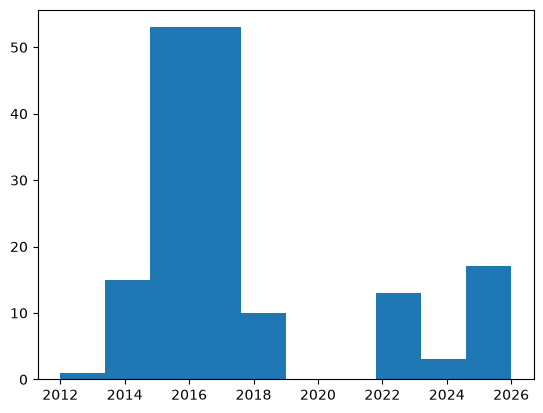

In [34]:
otras['post_date'] = pd.to_datetime(otras.post_date)

plt.hist(otras.post_year)

C:\Users\MAURICIO\AppData\Local\Temp\ipykernel_2280\3636177721.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


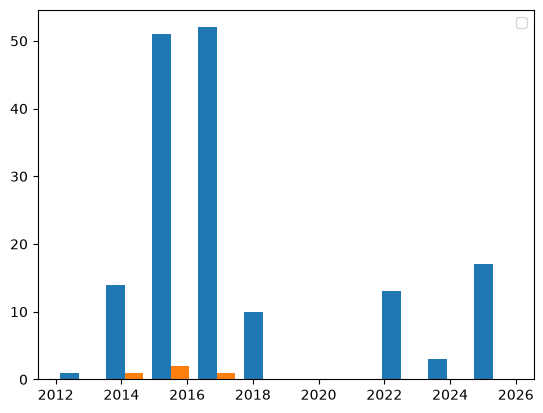

In [45]:
grupo_puras = otras.loc[otras['category'] == 'Otras', 'post_year']
grupo_secu = otras.loc[otras['category'] == 'Otras_secu', 'post_year']

plt.hist(
    [grupo_puras, grupo_secu]  
)

plt.legend()
plt.show()